https://github.com/sihsieh65-tech/cs82a-portfolio/tree/main/Module8

Import the data and run the standard data diagnostics



In [12]:
import pandas as pd
df = pd.read_csv('/content/lifecyclesavings.csv')
df

,Contry,sr,pop15,pop75,dpi,ddpi
0,Australia,11.43,29.35,2.87,2329.68,2.87
1,Austria,12.07,23.32,4.41,1507.99,3.93
2,Belgium,13.17,23.80,4.43,2108.47,3.82
3,Bolivia,5.75,41.89,1.67,189.13,0.22
4,Brazil,12.88,42.19,0.83,728.47,4.56
5,Canada,8.79,31.72,2.85,2982.88,2.43
6,Chile,0.60,39.74,1.34,662.86,2.67
7,China,11.90,44.75,0.67,289.52,6.51
8,Colombia,4.98,46.64,1.06,276.65,3.08
9,Costa Rica,10.78,47.64,1.14,471.24,2.80


In [13]:
df.shape

(50, 6)

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Contry  50 non-null     object 
 1   sr      50 non-null     float64
 2   pop15   50 non-null     float64
 3   pop75   50 non-null     float64
 4   dpi     50 non-null     float64
 5   ddpi    50 non-null     float64
dtypes: float64(5), object(1)
memory usage: 2.5+ KB


In [15]:
df.describe()

,sr,pop15,pop75,dpi,ddpi
count,50.000000,50.000000,50.000000,50.000000,50.000000
mean,9.671000,35.089600,2.293000,1106.758400,3.757600
std,4.480407,9.151727,1.290771,990.868889,2.869871
min,0.600000,21.440000,0.560000,88.940000,0.220000
25%,6.970000,26.215000,1.125000,288.207500,2.002500
50%,10.510000,32.575000,2.175000,695.665000,3.000000
75%,12.617500,44.065000,3.325000,1795.622500,4.477500
max,21.100000,47.640000,4.700000,4001.890000,16.710000


Prompted gemini with the following:

"You are helping with exploratory data analysis.

My CSV has columns:
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Contry  50 non-null     object
 1   sr      50 non-null     float64
 2   pop15   50 non-null     float64
 3   pop75   50 non-null     float64
 4   dpi     50 non-null     float64
 5   ddpi    50 non-null     float64
dtypes: float64(5), object(1)

Write Python using pandas and seaborn to:
(1) summarize missing data,
(2) compare [numeric column] across [category column],
(3) produce one labeled chart.
Explain each step in comments."

I ran the output below.

Gemini also provided the following breakdown:
Step-by-Step Breakdown

    Missing Data Summary: Uses .isnull().sum() and .mean() to compute the exact count and percentage of missing entries per column, ensuring data cleanliness is assessed upfront.

    Numeric vs. Category Comparison: Uses .groupby() paired with .agg() to generate statistical benchmarks (mean, median, min, max, std) for the numeric feature across each unique country.

    Labeled Visualization: Filters for the top 15 rows to prevent overcrowding, utilizing seaborn.barplot with custom titles, clean axis labels, and a professional color palette.

--- Missing Data Summary ---
        Missing Count  Missing Percentage (%)
Contry              0                     0.0
sr                  0                     0.0
pop15               0                     0.0
pop75               0                     0.0
dpi                 0                     0.0
ddpi                0                     0.0


--- Summary of sr across Contry (Top 10) ---
       Contry   mean  median    min    max  std
0   Australia  11.43   11.43  11.43  11.43  NaN
1     Austria  12.07   12.07  12.07  12.07  NaN
2     Belgium  13.17   13.17  13.17  13.17  NaN
3     Bolivia   5.75    5.75   5.75   5.75  NaN
4      Brazil  12.88   12.88  12.88  12.88  NaN
5      Canada   8.79    8.79   8.79   8.79  NaN
6       Chile   0.60    0.60   0.60   0.60  NaN
7       China  11.90   11.90  11.90  11.90  NaN
8    Colombia   4.98    4.98   4.98   4.98  NaN
9  Costa Rica  10.78   10.78  10.78  10.78  NaN




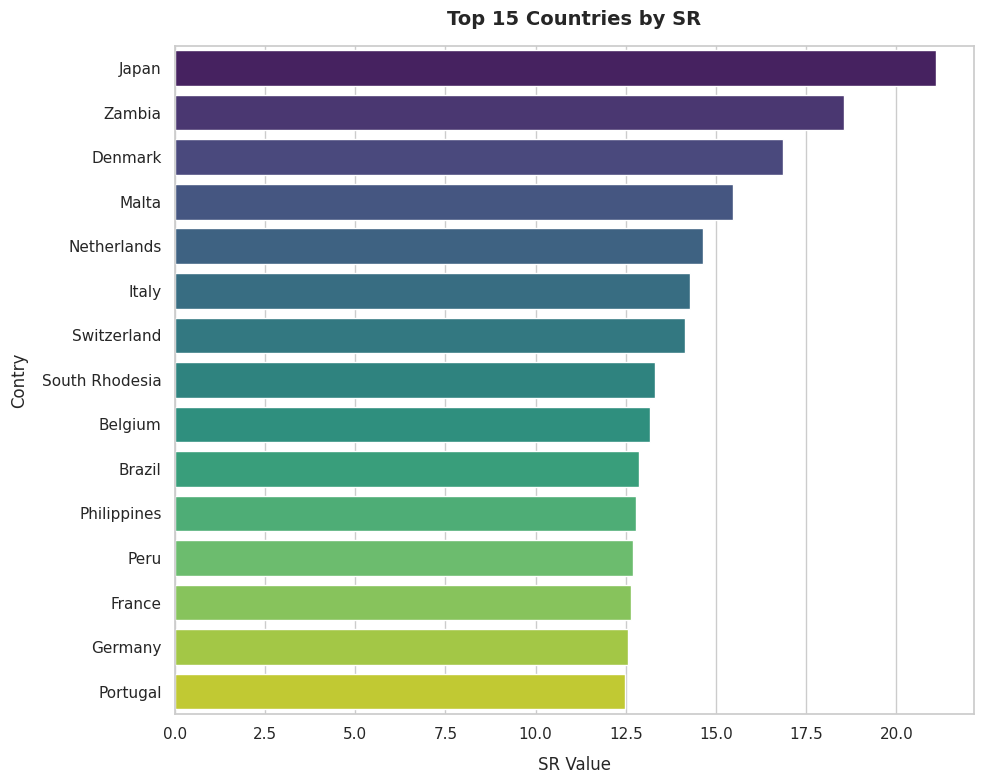

In [16]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load the dataset (replace 'your_data.csv' with your actual file path)
df = pd.read_csv('/content/lifecyclesavings.csv')

# =====================================================================
# Step 1: Summarize missing data
# =====================================================================
# Calculate total missing values and their percentage for each column
missing_count = df.isnull().sum()
missing_percent = (df.isnull().mean() * 100).round(2)

# Combine the results into a clear summary DataFrame
missing_summary = pd.DataFrame(
    {'Missing Count': missing_count, 'Missing Percentage (%)': missing_percent}
)

print('--- Missing Data Summary ---')
print(missing_summary)
print('\n' + '=' * 40 + '\n')

# =====================================================================
# Step 2: Compare numeric column across category column
# =====================================================================
# Define the columns to compare
numeric_col = 'sr'
category_col = 'Contry'

# Group by the category column and calculate summary statistics for the numeric column
comparison_summary = (
    df.groupby(category_col)[numeric_col]
    .agg(['mean', 'median', 'min', 'max', 'std'])
    .reset_index()
)

print(f'--- Summary of {numeric_col} across {category_col} (Top 10) ---')
print(comparison_summary.head(10))
print('\n' + '=' * 40 + '\n')

# =====================================================================
# Step 3: Produce one labeled chart
# =====================================================================
# Set up the visualization style
sns.set_theme(style='whitegrid')
plt.figure(figsize=(10, 8))

# Select top 15 countries sorted by the numeric column to keep the chart clean and readable
plot_data = df.sort_values(by=numeric_col, ascending=False).head(15)

# Create a horizontal bar plot comparing the numeric column across countries
sns.barplot(
    data=plot_data,
    x=numeric_col,
    y=category_col,
    palette='viridis',
    hue=category_col,
    legend=False
)

# Add descriptive title, axis labels, and formatting
plt.title(f'Top 15 Countries by {numeric_col.upper()}', fontsize=14, fontweight='bold', pad=15)
plt.xlabel(f'{numeric_col.upper()} Value', fontsize=12, labelpad=10)
plt.ylabel(category_col, fontsize=12, labelpad=10)

# Adjust layout so labels fit nicely and display the chart
plt.tight_layout()
plt.show()

After repeating the basics from lab 1 I added a follow-up prompt:

"Also cluster the countries into groups based on the data"

Gemini responded with the following explanation:

To cluster the countries into distinct groups based on their economic and demographic features (sr, pop15, pop75, dpi, ddpi), we can use K-Means clustering from scikit-learn.

Because these features are on very different scales (e.g., percentages vs. income values), we first need to standardize the data so every feature contributes equally to the clustering algorithm.

--- Countries Grouped into 3 Clusters ---

Cluster 0:
Bolivia, Chile, Colombia, Costa Rica, Ecuador, Guatamala, Honduras, India, Korea, Nicaragua, Panama, Paraguay, Peru, Philippines, Turkey, Tunisia, Venezuela, Malaysia

Cluster 1:
Brazil, China, Japan, Malta, Portugal, South Rhodesia, Zambia, Jamaica, Libya

Cluster 2:
Australia, Austria, Belgium, Canada, Denmark, Finland, France, Germany, Greece, Iceland, Ireland, Italy, Luxembourg, Norway, Netherlands, New Zealand, South Africa, Spain, Sweden, Switzerland, United Kingdom, United States, Uruguay




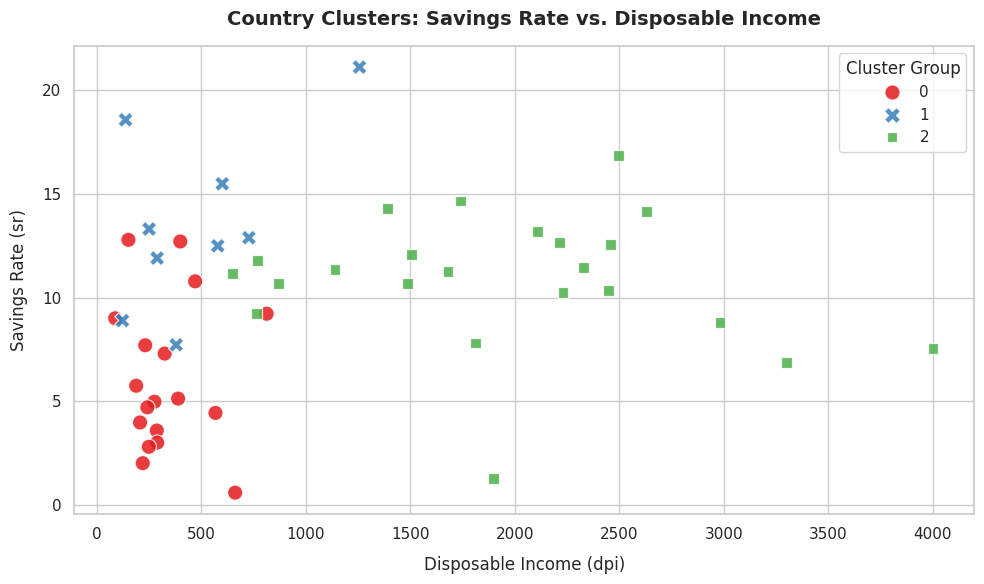

In [17]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load the dataset (replace 'your_data.csv' with your actual file path)
df = pd.read_csv('/content/lifecyclesavings.csv')

# =====================================================================
# Step 1: Prepare and Standardize Data for Clustering
# =====================================================================
# Select the numeric feature columns (excluding the country name)
feature_cols = ['sr', 'pop15', 'pop75', 'dpi', 'ddpi']
X = df[feature_cols]

# Standardize features (mean = 0, variance = 1) to give them equal weight
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# =====================================================================
# Step 2: Apply K-Means Clustering
# =====================================================================
# Choose the number of clusters (e.g., k=3 groups)
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

# Fit the model and assign cluster labels back to our dataframe
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Display the countries grouped by their assigned cluster
print(f'--- Countries Grouped into {k} Clusters ---')
for cluster_id in range(k):
  countries_in_cluster = df[df['Cluster'] == cluster_id]['Contry'].tolist()
  print(f'\nCluster {cluster_id}:')
  print(', '.join(countries_in_cluster))

print('\n' + '=' * 50 + '\n')

# =====================================================================
# Step 3: Visualize the Clusters
# =====================================================================
# Set up the visualization style
sns.set_theme(style='whitegrid')
plt.figure(figsize=(10, 6))

# Create a scatter plot comparing Disposable Income (dpi) vs Savings Rate (sr), colored by Cluster
sns.scatterplot(
    data=df,
    x='dpi',
    y='sr',
    hue='Cluster',
    palette='Set1',
    s=120,
    style='Cluster',
    alpha=0.85,
)

# Add title, labels, and formatting
plt.title(
    'Country Clusters: Savings Rate vs. Disposable Income',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Disposable Income (dpi)', fontsize=12, labelpad=10)
plt.ylabel('Savings Rate (sr)', fontsize=12, labelpad=10)
plt.legend(title='Cluster Group', loc='upper right')

# Adjust layout and display chart
plt.tight_layout()
plt.show()

Gemini also provided the following explanation:

Explanation of the StepsFeature Scaling (StandardScaler): Features like dpi (income) have much larger numerical ranges than features like pop75 (percentage). Scaling ensures that K-Means doesn't bias toward features with larger absolute values.

K-Means Algorithm: We group the 50 countries into $k=3$ distinct clusters based on similarities across all 5 variables. You can adjust $k$ (e.g., to 4 or 5) depending on how granular you want the groupings to be.

Cluster Visualization: The scatter plot maps Disposable Income (dpi) against Savings Rate (sr), color-coding each country by its assigned cluster so you can easily spot economic similarities and outliers.

Verification

In [18]:
df

,Contry,sr,pop15,pop75,dpi,ddpi,Cluster
0,Australia,11.43,29.35,2.87,2329.68,2.87,2
1,Austria,12.07,23.32,4.41,1507.99,3.93,2
2,Belgium,13.17,23.80,4.43,2108.47,3.82,2
3,Bolivia,5.75,41.89,1.67,189.13,0.22,0
4,Brazil,12.88,42.19,0.83,728.47,4.56,1
5,Canada,8.79,31.72,2.85,2982.88,2.43,2
6,Chile,0.60,39.74,1.34,662.86,2.67,0
7,China,11.90,44.75,0.67,289.52,6.51,1
8,Colombia,4.98,46.64,1.06,276.65,3.08,0
9,Costa Rica,10.78,47.64,1.14,471.24,2.80,0


In [19]:
df.groupby('Cluster')[['sr','pop15','pop75','dpi','ddpi']].mean()

,sr,pop15,pop75,dpi,ddpi
Cluster,,,,,
0,6.138889,44.556111,1.079444,337.153333,2.359444
1,13.591111,37.492222,1.623333,483.241111,7.662222
2,10.901304,26.740870,3.504783,1953.043043,3.323913


Verify and interpret

Based on the means it appears the clustering was successful. The most prominent differences in the cluters appear to be in the savings rate (sr) with cluster 0 being very different from the others and with the disposable income (dpi) and its percent of population over 75 (pop75) with cluster 2 being very different from others as well. Cluster 1 appears to distinguish itself based on the disposible income growth rate (ddpi). The caution in using this method is that I do not have prior experience with it and therefore can only look for obvious problems. I cannot really determine if there were any subtle manipulations done to the data that would impact the results.